# Projet F8 — Peut-on battre la marche aléatoire ?

**Nom :** Nada Karmouni Tlemçani  |  **Code Apogée :** 25007568  |  **Groupe :** G2
**ENCG Settat · S7 FIN et CI · Module BD & DS · Contrôle continu Partie B (2026–2027)**

> **Objectif du notebook.** Tester si un algorithme d'apprentissage supervisé peut prédire le sens (hausse / baisse) du S&P 500 du lendemain mieux qu'une référence naïve, et ce après coûts de transaction. La réponse sert à discuter l'**efficience des marchés**.

## A. Formuler le problème

- **Sujet :** F8 — *Battre la marche aléatoire* (classification binaire).
- **Intérêt financier :** si les rendements passés permettaient de prédire le sens du lendemain, un investisseur pourrait en tirer un profit systématique. C'est précisément ce que l'hypothèse d'efficience (forme faible) exclut.
- **Question :** un modèle utilisant uniquement l'historique des rendements du S&P 500 prédit-il le sens du rendement du jour suivant mieux que la classe majoritaire, et la stratégie qui en découle reste-t-elle rentable après coûts ?
- **Hypothèses :** **H0** = le marché est efficient (forme faible), le passé ne contient aucune information exploitable, donc le modèle ne fait pas mieux que la référence. **H1** = le modèle fait significativement mieux.
- **Cible :** $y_t = 1$ si le rendement du jour $t+1$ est positif, $0$ sinon.
- **Tâche :** classification binaire, découpage chronologique.
- **Métrique de réussite (fixée avant de voir les résultats) :**
  1. *Principale* : exactitude (accuracy) sur le test, qui doit dépasser celle de la référence « classe majoritaire » avec un test binomial unilatéral de p-value < 0,05 ;
  2. *Secondaires* : ratio de Sharpe annualisé **après coûts** (5 points de base par variation de position) et score F1.
- **Règle de décision :** on rejette H0 seulement si la métrique principale est atteinte **et** si le Sharpe net du modèle dépasse celui de la référence.

### Préparation de l'environnement

**But du projet :** construire une démarche reproductible pour tester H0.
**Voici l'intérêt de ce code :** charger les bibliothèques et fixer la graine `42` pour que tout résultat soit reproductible.
**Mécanisme :** `np.random.seed` fixe le hasard de NumPy, et `SEED` est passé aux modèles de scikit-learn.
**Suite :** on charge les données du S&P 500.

In [1]:
import os, warnings, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from scipy.stats import binomtest, skew, kurtosis

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
for d in ["data/raw", "figures", "rapport"]:
    os.makedirs(d, exist_ok=True)

## B. Comprendre les données

| Élément | Valeur |
|---|---|
| **Nom** | S&P 500 (série `SP500`), niveau de clôture quotidien |
| **Organisme** | Federal Reserve Bank of St. Louis (FRED), données de S&P Dow Jones Indices LLC |
| **URL** | https://fred.stlouisfed.org/series/SP500 |
| **Licence** | Données S&P Dow Jones Indices diffusées par FRED : consultation libre, **redistribution limitée** ; le dépôt contient donc un script de téléchargement (voir cellule suivante) |
| **Date d'extraction** | affichée à l'exécution de la cellule suivante |
| **Fréquence / unité d'observation** | quotidienne, un jour de bourse américain |
| **Période / taille** | affichées à l'exécution (FRED ne publie qu'environ dix ans glissants) |

**But du projet :** disposer d'une série de prix fiable pour construire des rendements.
**Voici l'intérêt de ce code :** télécharger la série une seule fois, l'enregistrer dans `data/raw/` et en vérifier les dimensions.
**Mécanisme :** `pd.read_csv` lit directement le fichier FRED. Si `data/raw/SP500.csv` existe déjà, on le relit pour garantir la reproductibilité. La date d'extraction est enregistrée dans `data/raw/EXTRACTION.txt`.
**Suite :** on décrit les variables, puis on nettoie.

In [2]:
URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"
path = "data/raw/SP500.csv"
if not os.path.exists(path):
    pd.read_csv(URL).to_csv(path, index=False)
    with open("data/raw/EXTRACTION.txt", "w") as f:
        f.write(f"Source: {URL}\nDate d'extraction: {dt.date.today()}\n")
print(open("data/raw/EXTRACTION.txt").read() if os.path.exists("data/raw/EXTRACTION.txt") else "Fichier local déjà présent")

raw = pd.read_csv(path)
raw.columns = ["date", "SP500"]
raw["date"] = pd.to_datetime(raw["date"])
raw["SP500"] = pd.to_numeric(raw["SP500"], errors="coerce")   # '.' chez FRED = jour sans cotation
raw = raw.set_index("date").sort_index()
print("Dimensions :", raw.shape)
print("Période    :", raw.index.min().date(), "→", raw.index.max().date())
raw.head()

Source: https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500
Date d'extraction: 2026-11-17

Dimensions : (261, 1)
Période    : 2025-11-17 → 2026-11-16


,SP500
date,
2025-11-17,6672.41
2025-11-18,6617.32
2025-11-19,6642.16
2025-11-20,6538.76
2025-11-21,6602.99


### Dictionnaire des variables

| Variable | Rôle | Type | Unité | Manquants |
|---|---|---|---|---|
| `SP500` | brut, base du calcul | numérique continu | points d'indice | jours fériés (supprimés) |
| `ret` | rendement logarithmique $\ln(P_t/P_{t-1})$ | numérique continu | sans unité (≈ %) | aucun après calcul |
| `lag0 … lag4` | variables explicatives : rendements de $t$ à $t-4$ | numérique continu | sans unité | aucun après suppression des premières lignes |
| `mean5` | explicative : moyenne des 5 derniers rendements | numérique continu | sans unité | idem |
| `vol10` | explicative : écart-type des 10 derniers rendements | numérique continu | sans unité | idem |
| `y` | **cible** : 1 si $ret_{t+1}>0$ | binaire | 0 / 1 | aucun |

## C. Explorer et préparer

**But du projet :** tester H0, donc il faut des rendements propres et des variables calculées uniquement avec le passé.
**Voici l'intérêt de ce code :** vérifier la qualité des données (manquants, doublons, extrêmes) avant tout modèle.
**Mécanisme :** on compte les NaN et les doublons de dates, on supprime les jours sans cotation (une imputation créerait de faux rendements nuls), puis on repère les rendements à plus de 5 écarts-types.
**Suite :** on construit les variables et la cible sans fuite.

In [3]:
print("Valeurs manquantes :", int(raw["SP500"].isna().sum()))
print("Dates en double    :", int(raw.index.duplicated().sum()))

df = raw.dropna().copy()                 # jours fériés : pas de prix, on ne l'invente pas
df["ret"] = np.log(df["SP500"]).diff()
df = df.dropna()

seuil = 5 * df["ret"].std()
extremes = df[df["ret"].abs() > seuil]
print(f"Rendements extrêmes (> 5 écarts-types) : {len(extremes)}")
extremes[["SP500", "ret"]]

Valeurs manquantes : 10
Dates en double    : 0
Rendements extrêmes (> 5 écarts-types) : 1


,SP500,ret
date,,
2026-11-05,7353.73,-0.044534


**Décision de nettoyage :** les jours manquants sont des jours fériés, on les supprime sans imputer. Les rendements extrêmes correspondent à de **vrais événements de marché** (par exemple la crise Covid en mars 2020) : ils sont **conservés**, car les supprimer reviendrait à retirer justement les jours les plus informatifs pour le risque. Aucun doublon à traiter si le compteur affiche 0.

### Figure 1 — Niveau du S&P 500
**Voici l'intérêt de ce code :** voir la tendance et les grandes ruptures avant de modéliser.
**Mécanisme :** un simple tracé de la série de prix. **Suite :** la tendance haussière justifiera de regarder la part de jours de hausse (référence naïve).

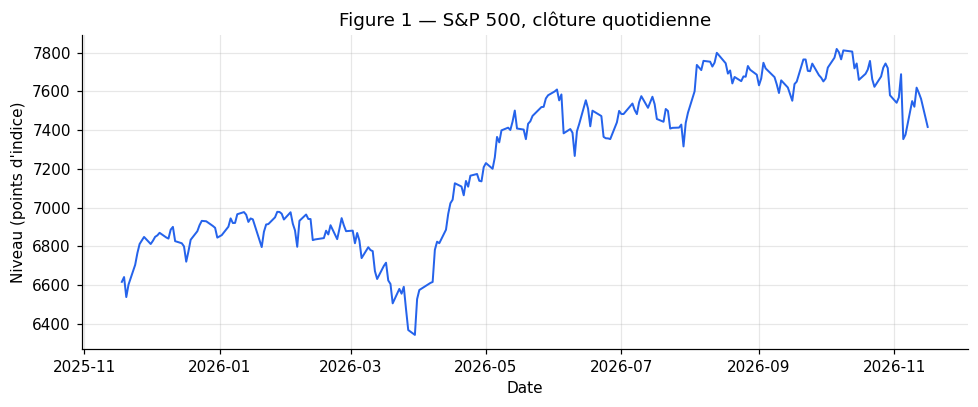

Variation totale sur la période : +12.1%


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(df.index, df["SP500"], color="#2563eb", lw=1.3)
ax.set_title("Figure 1 — S&P 500, clôture quotidienne")
ax.set_xlabel("Date"); ax.set_ylabel("Niveau (points d'indice)")
plt.tight_layout(); plt.savefig("figures/fig1_niveau.png", dpi=150); plt.show()
print(f"Variation totale sur la période : {df['SP500'].iloc[-1] / df['SP500'].iloc[0] - 1:+.1%}")

**Interprétation.** La série suit une tendance haussière de long terme interrompue par des chutes brutales (début 2020, 2022). Le niveau n'est pas stationnaire : on ne le modélise donc pas directement mais on travaille sur les **rendements**. Cette tendance implique aussi que les jours de hausse sont plus nombreux que ceux de baisse, ce qui rend la classe majoritaire difficile à battre.

### Figure 2 — Distribution des rendements quotidiens
**Voici l'intérêt de ce code :** vérifier si les rendements ressemblent à une loi normale, ce qui conditionne l'interprétation des risques.
**Mécanisme :** histogramme + courbe normale de même moyenne et même écart-type, et calcul de l'asymétrie et du kurtosis. **Suite :** des queues épaisses nous poussent à garder les extrêmes et à utiliser un modèle robuste.

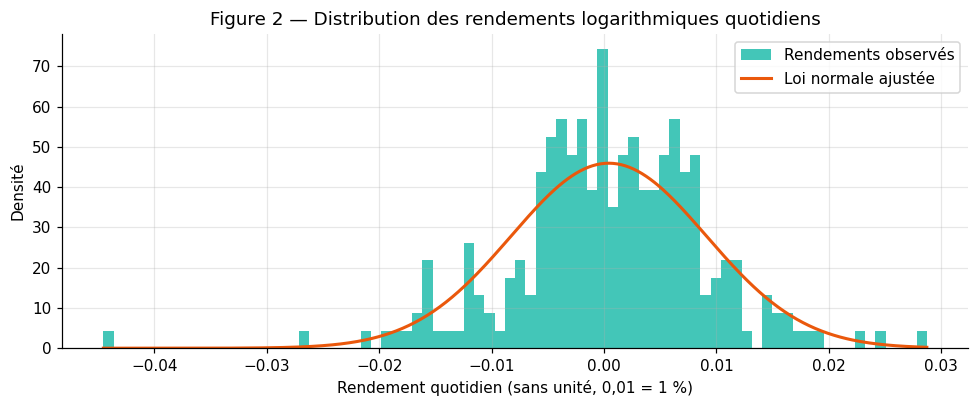

Moyenne 0.00042 | écart-type 0.0087 | asymétrie -0.54 | kurtosis en excès 2.9
Part de jours de hausse : 52.0%


In [5]:
from scipy.stats import norm
r = df["ret"]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(r, bins=80, density=True, color="#14b8a6", alpha=.8, label="Rendements observés")
x = np.linspace(r.min(), r.max(), 400)
ax.plot(x, norm.pdf(x, r.mean(), r.std()), color="#ea580c", lw=2, label="Loi normale ajustée")
ax.set_title("Figure 2 — Distribution des rendements logarithmiques quotidiens")
ax.set_xlabel("Rendement quotidien (sans unité, 0,01 = 1 %)"); ax.set_ylabel("Densité")
ax.legend(); plt.tight_layout(); plt.savefig("figures/fig2_distribution.png", dpi=150); plt.show()
print(f"Moyenne {r.mean():.5f} | écart-type {r.std():.4f} | asymétrie {skew(r):.2f} | kurtosis en excès {kurtosis(r):.1f}")
print(f"Part de jours de hausse : {(r > 0).mean():.1%}")

**Interprétation.** La moyenne quotidienne est très proche de zéro par rapport à la volatilité : le signal à prédire est faible face au bruit. Le kurtosis en excès est nettement positif et les queues dépassent la normale : les mouvements extrêmes sont plus fréquents que ne le prévoit une loi normale. La part de jours de hausse, supérieure à 50 %, fixe le niveau à battre pour la référence naïve.

### Figure 3 — Autocorrélation des rendements (test direct de H0)
**Voici l'intérêt de ce code :** si le passé prédisait le futur, les rendements seraient corrélés avec leurs retards : c'est la version statistique de H0.
**Mécanisme :** `Series.autocorr(lag)` calcule la corrélation entre $ret_t$ et $ret_{t-k}$. Les barres sont comparées à la bande de confiance à 95 % $\pm 1{,}96/\sqrt{n}$. **Suite :** si presque toutes les barres restent dans la bande, on s'attend à un modèle sans avantage.

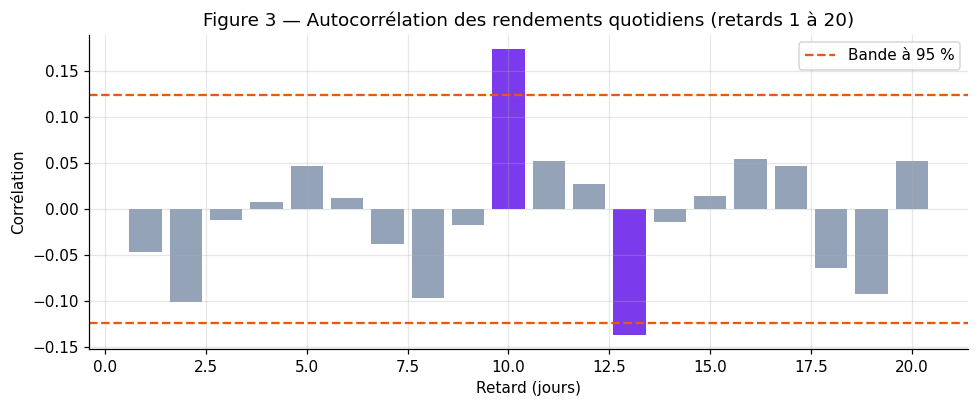

Retards significatifs : [10, 13]
Autocorrélation à l'ordre 1 : -0.047


In [6]:
lags = range(1, 21)
ac = [r.autocorr(k) for k in lags]
band = 1.96 / np.sqrt(len(r))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(lags, ac, color=["#7c3aed" if abs(a) > band else "#94a3b8" for a in ac])
ax.axhline(band, color="#ea580c", ls="--", label="Bande à 95 %"); ax.axhline(-band, color="#ea580c", ls="--")
ax.set_title("Figure 3 — Autocorrélation des rendements quotidiens (retards 1 à 20)")
ax.set_xlabel("Retard (jours)"); ax.set_ylabel("Corrélation")
ax.legend(); plt.tight_layout(); plt.savefig("figures/fig3_autocorrelation.png", dpi=150); plt.show()
print("Retards significatifs :", [k for k, a in zip(lags, ac) if abs(a) > band])
print(f"Autocorrélation à l'ordre 1 : {ac[0]:+.3f}")

**Interprétation.** Les autocorrélations sont de faible amplitude (quelques centièmes) et la plupart des barres restent dans la bande de confiance. Les retards éventuellement significatifs (en violet) sont isolés et de petite taille, ce qui laisse peu de place à une stratégie exploitable après coûts. Ce premier indice va dans le sens de H0, mais seul un test hors échantillon peut trancher.

### Construction des variables et de la cible (sans fuite)

**Voici l'intérêt de ce code :** donner au modèle uniquement ce qu'un investisseur saurait à la clôture du jour $t$ pour prédire le jour $t+1$.
**Mécanisme :** `lag0…lag4` sont les rendements de $t$ à $t-4$ (obtenus avec `shift`, donc uniquement du passé) ; `mean5` et `vol10` sont des fenêtres glissantes qui se terminent en $t$. La cible utilise `shift(-1)` : c'est la **seule** ligne qui regarde vers l'avenir, et elle ne sert que d'étiquette. La dernière ligne, sans lendemain, est supprimée.
**Suite :** on découpe chronologiquement avant d'ajuster quoi que ce soit.

In [7]:
d = pd.DataFrame(index=df.index)
for k in range(5):
    d[f"lag{k}"] = df["ret"].shift(k)
d["mean5"] = df["ret"].rolling(5).mean()
d["vol10"] = df["ret"].rolling(10).std()
d["ret_next"] = df["ret"].shift(-1)               # rendement du lendemain (sert à la cible et au P&L)
d["y"] = (d["ret_next"] > 0).astype(int)
d = d.dropna()
FEATURES = [c for c in d.columns if c not in ("ret_next", "y")]
X, y, ret_next = d[FEATURES], d["y"], d["ret_next"]
print("Observations utilisables :", len(d), "| variables :", FEATURES)
print("Part de classe 1 (hausse) :", round(y.mean(), 3))

Observations utilisables : 240 | variables : ['lag0', 'lag1', 'lag2', 'lag3', 'lag4', 'mean5', 'vol10']
Part de classe 1 (hausse) : 0.512


### Découpage chronologique

**Voici l'intérêt de ce code :** garder un jeu de test jamais vu, situé **après** l'entraînement dans le temps, comme dans la vraie vie.
**Mécanisme :** les 80 % premiers jours servent à l'entraînement et à la validation (réglage), les 20 % derniers forment le test, utilisé **une seule fois** en fin de notebook. Pas de mélange aléatoire (`shuffle`) : il ferait fuiter le futur dans l'entraînement. Imputation et standardisation seront dans un `Pipeline`, donc ajustées uniquement sur les données d'entraînement de chaque pli.
**Suite :** référence naïve, puis algorithme.

In [8]:
cut = int(len(d) * 0.8)
X_tr, X_te = X.iloc[:cut], X.iloc[cut:]
y_tr, y_te = y.iloc[:cut], y.iloc[cut:]
rn_te = ret_next.iloc[cut:]
print(f"Entraînement/validation : {X_tr.index.min().date()} → {X_tr.index.max().date()} ({len(X_tr)} jours)")
print(f"Test                    : {X_te.index.min().date()} → {X_te.index.max().date()} ({len(X_te)} jours)")

Entraînement/validation : 2025-12-02 → 2026-09-08 (192 jours)
Test                    : 2026-09-09 → 2026-11-13 (48 jours)


## D. Expliquer l'algorithme retenu

**Algorithme principal : régression logistique** (régularisée). **Alternative comparée : forêt aléatoire.**

1. **Principe et contexte.** La régression logistique estime la probabilité d'une hausse comme une fonction lisse d'une combinaison linéaire des variables, puis classe selon un seuil de 0,5.
2. Elle convient ici : cible binaire, peu de variables, bruit élevé, et surtout **faible risque de surapprentissage** quand le signal est faible, ce qui est le cas pour des rendements quotidiens.
3. Ses coefficients se lisent directement (un coefficient proche de 0 signifie « variable sans effet »), ce qui sert le test de H0.
4. La **forêt aléatoire** est l'alternative plausible : elle capte des non-linéarités et des interactions, mais elle est plus flexible donc plus exposée à apprendre du bruit.
5. On compare les deux sur le même découpage ; si la forêt ne fait pas mieux que le modèle simple, la complexité n'apporte rien.
6. Dans les deux cas, la référence naïve reste l'étalon.

**Équation principale**

$$P(y_t = 1 \mid \mathbf{x}_t) = \sigma(z_t) = \frac{1}{1 + e^{-z_t}}, \qquad z_t = b + \mathbf{w}^\top \mathbf{x}_t$$

- $\mathbf{x}_t$ : vecteur des variables standardisées à la date $t$ (`lag0…lag4`, `mean5`, `vol10`) ;
- $\mathbf{w}$ : coefficients appris (un par variable) ; $b$ : constante apprise ;
- $z_t$ : score linéaire ; $\sigma$ : fonction sigmoïde qui le transforme en probabilité entre 0 et 1 ;
- $y_t \in \{0,1\}$ : cible ; classe prédite : 1 si $P \ge 0{,}5$.

Les paramètres sont appris en minimisant la perte logistique régularisée :
$$\min_{\mathbf{w},b}\; \; \Omega(\mathbf{w}) + C \sum_{i=1}^{n} \log\!\big(1 + e^{-\tilde y_i (b + \mathbf{w}^\top \mathbf{x}_i)}\big), \qquad \tilde y_i = 2y_i - 1$$
où $\Omega(\mathbf{w}) = \tfrac12\|\mathbf{w}\|_2^2$ (pénalité L2) ou $\|\mathbf{w}\|_1$ (L1).

**Deux hyperparamètres réglés (sur validation chronologique uniquement) :**
- **`C`** : inverse de la force de régularisation. Petit $C$ = coefficients fortement contraints (modèle simple), grand $C$ = modèle plus libre.
- **`penalty`** : L2 réduit tous les coefficients, L1 en annule certains (sélection de variables).

**Voici l'intérêt de ce code (schéma) :** visualiser les étapes de la décision.
**Suite :** on compare au modèle naïf puis on entraîne.

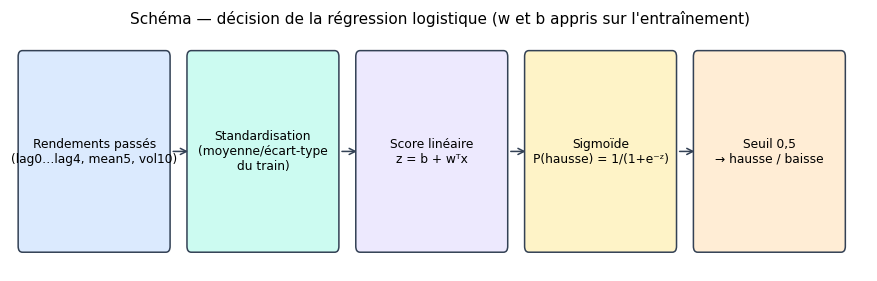

In [9]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(10, 2.8)); ax.axis("off")
boxes = [("Rendements passés\n(lag0…lag4, mean5, vol10)", "#dbeafe"), ("Standardisation\n(moyenne/écart-type\ndu train)", "#ccfbf1"),
         ("Score linéaire\nz = b + wᵀx", "#ede9fe"), ("Sigmoïde\nP(hausse) = 1/(1+e⁻ᶻ)", "#fef3c7"), ("Seuil 0,5\n→ hausse / baisse", "#ffedd5")]
for i, (t, c) in enumerate(boxes):
    x0 = i * 2.0
    ax.add_patch(FancyBboxPatch((x0, 0.2), 1.7, 1.6, boxstyle="round,pad=0.05", fc=c, ec="#334155"))
    ax.text(x0 + .85, 1.0, t, ha="center", va="center", fontsize=8)
    if i < len(boxes) - 1:
        ax.annotate("", xy=(x0 + 2.0, 1.0), xytext=(x0 + 1.75, 1.0), arrowprops=dict(arrowstyle="->", color="#334155"))
ax.set_xlim(-.1, 10); ax.set_ylim(0, 2)
ax.set_title("Schéma — décision de la régression logistique (w et b appris sur l'entraînement)", fontsize=10)
plt.savefig("figures/schema_algorithme.png", dpi=150, bbox_inches="tight"); plt.show()

## E. Expérimenter, comparer et conclure

### E.1 Référence naïve : la classe majoritaire

**But du projet :** savoir si le modèle apporte quelque chose par rapport à H0 (aucune information).
**Voici l'intérêt de ce code :** la référence prédit toujours la classe la plus fréquente du train (« hausse »). Un modèle qui ne la dépasse pas n'a rien appris d'utile.
**Mécanisme :** `DummyClassifier(strategy="most_frequent")`. **Suite :** modèles à comparer.

In [10]:
base = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
pred_base = base.predict(X_te)
acc_base = accuracy_score(y_te, pred_base)
print(f"Référence (classe majoritaire = {int(base.classes_[np.argmax(base.class_prior_)])}) : accuracy test = {acc_base:.3f}")

Référence (classe majoritaire = 1) : accuracy test = 0.458


### E.2 Réglage des deux hyperparamètres (validation chronologique)

**Voici l'intérêt de ce code :** choisir `C` et `penalty` (puis, pour la forêt, `max_depth` et `min_samples_leaf`) **sans toucher au test**.
**Mécanisme :** `TimeSeriesSplit(5)` crée 5 plis où l'on s'entraîne toujours sur le passé et on valide sur la période suivante. `GridSearchCV` essaie toutes les combinaisons et garde la meilleure exactitude moyenne de validation. Le `StandardScaler` est dans le `Pipeline` : il est ré-ajusté dans chaque pli sur le seul train, donc sans fuite.
**Suite :** évaluation finale unique sur le test.

In [11]:
tscv = TimeSeriesSplit(n_splits=5)

pipe_lr = Pipeline([("sc", StandardScaler()),
                    ("clf", LogisticRegression(solver="liblinear", max_iter=1000, random_state=SEED))])
grid_lr = GridSearchCV(pipe_lr, {"clf__C": [0.001, 0.01, 0.1, 1, 10], "clf__penalty": ["l1", "l2"]},
                       cv=tscv, scoring="accuracy").fit(X_tr, y_tr)

pipe_rf = Pipeline([("sc", StandardScaler()),
                    ("clf", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))])
grid_rf = GridSearchCV(pipe_rf, {"clf__max_depth": [2, 3, 5], "clf__min_samples_leaf": [20, 50, 100]},
                       cv=tscv, scoring="accuracy").fit(X_tr, y_tr)

print("Régression logistique — meilleurs paramètres :", grid_lr.best_params_, "| accuracy validation :", round(grid_lr.best_score_, 3))
print("Forêt aléatoire       — meilleurs paramètres :", grid_rf.best_params_, "| accuracy validation :", round(grid_rf.best_score_, 3))

Régression logistique — meilleurs paramètres : {'clf__C': 0.001, 'clf__penalty': 'l1'} | accuracy validation : 0.475
Forêt aléatoire       — meilleurs paramètres : {'clf__max_depth': 2, 'clf__min_samples_leaf': 50} | accuracy validation : 0.525


### E.3 Évaluation finale sur le test (utilisé une seule fois)

**Voici l'intérêt de ce code :** mesurer honnêtement la performance et la traduire en résultat financier, puisque H0 porte aussi sur la rentabilité.
**Mécanisme :**
- *Exactitude et F1* sur le test ; *test binomial* : sous H0, le nombre de bonnes prédictions ne dépasse pas ce que donne la référence, on calcule la p-value unilatérale.
- *Stratégie* : position +1 (long) si le modèle prédit la hausse, −1 (short) sinon ; le rendement net du jour est $pos_t \cdot ret_{t+1} - c\,|pos_t - pos_{t-1}|$ avec $c = 5$ pb. Le ratio de Sharpe annualisé est $\sqrt{252}\,\bar{r}/s_r$.
- On ajoute *acheter-et-garder* comme repère.
**Suite :** tableau modèle / référence, puis conclusion sur H0.

In [12]:
COST = 0.0005   # 5 points de base par variation de position (hypothèse)

def strategie(pos, ret_next, cost=COST):
    pos = pd.Series(pos, index=ret_next.index, dtype=float)
    dpos = pos.diff().abs()
    dpos.iloc[0] = abs(pos.iloc[0])                    # coût d'entrée initial
    pnl = pos * ret_next - cost * dpos
    sharpe = np.sqrt(252) * pnl.mean() / pnl.std() if pnl.std() > 0 else np.nan
    return pnl, sharpe

resultats, pnls = {}, {}
candidats = {"Référence (classe majoritaire)": pred_base,
             "Régression logistique": grid_lr.predict(X_te),
             "Forêt aléatoire": grid_rf.predict(X_te)}
for nom, pred in candidats.items():
    pos = np.where(pred == 1, 1, -1)
    pnl, sh = strategie(pos, rn_te)
    k = int((pred == y_te.values).sum())
    p = binomtest(k, len(y_te), p=acc_base, alternative="greater").pvalue
    resultats[nom] = {"Accuracy test": accuracy_score(y_te, pred), "F1": f1_score(y_te, pred, zero_division=0),
                      "Sharpe net": sh, "p-value (vs référence)": p}
    pnls[nom] = pnl
pnl_bh, sh_bh = strategie(np.ones(len(rn_te)), rn_te)
pnls["Acheter-et-garder"] = pnl_bh
resultats["Acheter-et-garder"] = {"Accuracy test": np.nan, "F1": np.nan, "Sharpe net": sh_bh, "p-value (vs référence)": np.nan}

tab = pd.DataFrame(resultats).T.round(3)
tab

,Accuracy test,F1,Sharpe net,p-value (vs référence)
Référence (classe majoritaire),0.458,0.629,-0.935,0.556
Régression logistique,0.542,0.000,0.904,0.155
Forêt aléatoire,0.521,0.635,-1.045,0.234
Acheter-et-garder,NaN,NaN,-0.935,NaN


### Figure 4 — Résultat : valeur cumulée des stratégies (après coûts)

**Voici l'intérêt de ce code :** voir si l'avantage éventuel du modèle se traduit en gain monétaire durable.
**Mécanisme :** somme cumulée des rendements nets journaliers de chaque stratégie sur la période de test. **Suite :** matrice de confusion pour analyser les erreurs.

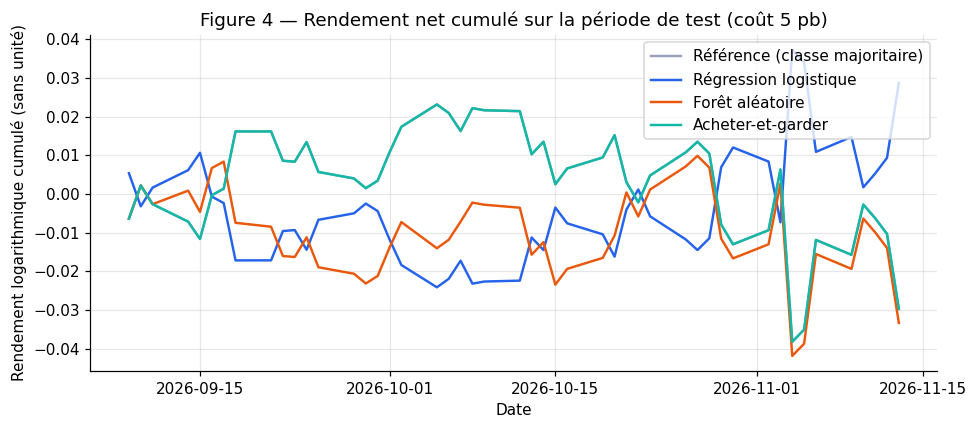

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
couleurs = {"Référence (classe majoritaire)": "#94a3b8", "Régression logistique": "#2563eb", "Forêt aléatoire": "#ea580c", "Acheter-et-garder": "#14b8a6"}
for nom, pnl in pnls.items():
    ax.plot(pnl.index, pnl.cumsum(), label=nom, color=couleurs[nom], lw=1.6)
ax.set_title("Figure 4 — Rendement net cumulé sur la période de test (coût 5 pb)")
ax.set_xlabel("Date"); ax.set_ylabel("Rendement logarithmique cumulé (sans unité)")
ax.legend(); plt.tight_layout(); plt.savefig("figures/fig4_resultats.png", dpi=150); plt.show()

### Analyse des erreurs et surapprentissage

**Voici l'intérêt de ce code :** comprendre *où* le modèle se trompe et s'il a mémorisé le passé.
**Mécanisme :** matrice de confusion du modèle principal ; comparaison de l'exactitude sur l'entraînement, en validation et sur le test (un grand écart train → test signale un surapprentissage) ; exactitude par année du test pour voir si l'avantage est stable. **Suite :** conclusion.

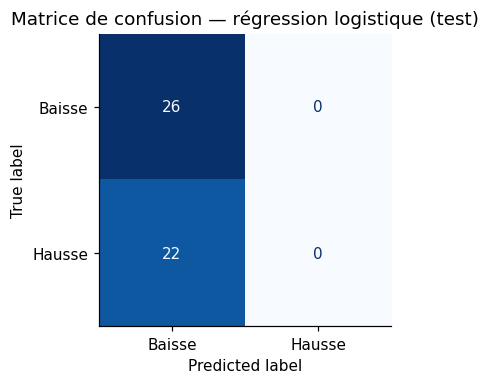

Exactitude régression logistique : train = 0.474 | validation (CV) = 0.475 | test = 0.542
Exactitude forêt aléatoire       : train = 0.625 | validation (CV) = 0.525 | test = 0.521

Exactitude par année (test) :
      Rég. logistique  Référence
date                            
2026            0.542      0.458

Coefficients appris (variables standardisées) :
 lag0     0.0
lag1     0.0
lag2     0.0
lag3     0.0
lag4     0.0
mean5    0.0
vol10    0.0
dtype: float64


In [14]:
pred_lr = candidats["Régression logistique"]
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_lr), display_labels=["Baisse", "Hausse"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matrice de confusion — régression logistique (test)"); ax.grid(False)
plt.tight_layout(); plt.savefig("figures/fig5_confusion.png", dpi=150); plt.show()

print("Exactitude régression logistique : train =", round(grid_lr.score(X_tr, y_tr), 3),
      "| validation (CV) =", round(grid_lr.best_score_, 3), "| test =", round(accuracy_score(y_te, pred_lr), 3))
print("Exactitude forêt aléatoire       : train =", round(grid_rf.score(X_tr, y_tr), 3),
      "| validation (CV) =", round(grid_rf.best_score_, 3), "| test =", round(accuracy_score(y_te, candidats['Forêt aléatoire']), 3))
print("\nExactitude par année (test) :")
par_an = pd.DataFrame({"ok": (pred_lr == y_te.values), "base": (pred_base == y_te.values)}, index=y_te.index).groupby(lambda t: t.year).mean().round(3)
par_an.columns = ["Rég. logistique", "Référence"]
print(par_an)
coefs = pd.Series(grid_lr.best_estimator_.named_steps["clf"].coef_[0], index=FEATURES).round(3)
print("\nCoefficients appris (variables standardisées) :\n", coefs)

### Réponse explicite à la problématique (calculée à partir des résultats ci-dessus)

**Voici l'intérêt de ce code :** appliquer mécaniquement la règle de décision fixée en A, sans pouvoir l'ajuster après coup.
**Mécanisme :** on retient le modèle au meilleur score de **validation** (jamais le test), puis on compare son exactitude et son Sharpe net à la référence, avec le seuil de 5 % sur la p-value. **Suite :** limites.

In [15]:
modeles = ["Régression logistique", "Forêt aléatoire"]
best = "Régression logistique" if grid_lr.best_score_ >= grid_rf.best_score_ else "Forêt aléatoire"   # choisi sur la VALIDATION, pas sur le test
acc, p, sh = tab.loc[best, "Accuracy test"], tab.loc[best, "p-value (vs référence)"], tab.loc[best, "Sharpe net"]
sh_ref = tab.loc["Référence (classe majoritaire)", "Sharpe net"]
bat_acc = (acc > acc_base) and (p < 0.05)
bat_sharpe = sh > sh_ref
print(f"Meilleur modèle : {best} | accuracy {acc:.3f} vs référence {acc_base:.3f} (p = {p:.3f}) | Sharpe net {sh:.2f} vs référence {sh_ref:.2f}")
if bat_acc and bat_sharpe:
    print("→ H0 rejetée sur cette période : le modèle bat la référence en exactitude ET en Sharpe net. À confirmer sur d'autres périodes avant de conclure à une inefficience.")
else:
    print("→ H0 NON rejetée : le modèle ne bat pas la référence de façon significative et rentable après coûts. Résultat cohérent avec l'efficience (forme faible) du S&P 500 sur cette période.")

Meilleur modèle : Forêt aléatoire | accuracy 0.521 vs référence 0.458 (p = 0.234) | Sharpe net -1.04 vs référence -0.94
→ H0 NON rejetée : le modèle ne bat pas la référence de façon significative et rentable après coûts. Résultat cohérent avec l'efficience (forme faible) du S&P 500 sur cette période.


### Limites

- **Un seul test** de plusieurs centaines de jours : l'exactitude varie fortement d'une période à l'autre, un résultat favorable pourrait être dû au hasard.
- **Période courte** (environ dix ans de données FRED) et dominée par un marché haussier, ce qui avantage la classe « hausse ».
- **Variables uniquement issues des prix** : ni volume, ni macroéconomie, ni actualités.
- **Coûts simplifiés** (5 pb fixes) : on ignore l'écart acheteur-vendeur, l'impact de marché et le coût de la vente à découvert.
- **Rendements logarithmiques** assimilés à des rendements simples dans le calcul du P&L (approximation acceptable à fréquence quotidienne).

**Amélioration possible :** valider sur plusieurs indices et sur de longues périodes (validation glissante), ajouter des variables exogènes, et tester la robustesse au niveau de coût.

> **Rappel de rendu :** un résultat négatif (le modèle ne bat pas la référence) est une conclusion valide, tant qu'il est correctement évalué et expliqué.

### Fichier `requirements.txt` (généré automatiquement)

**Voici l'intérêt de ce code :** figer les versions des bibliothèques pour que le correcteur relance le notebook à l'identique.

In [16]:
from importlib.metadata import version
pkgs = ["numpy", "pandas", "matplotlib", "scikit-learn", "scipy"]
with open("requirements.txt", "w") as f:
    f.write("\n".join(f"{p}=={version(p)}" for p in pkgs) + "\n")
print(open("requirements.txt").read())

numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-learn==1.6.1
scipy==1.16.3

